# Cleaned Steam Games: EDA for Supervised and Unsupervised Learning

**Goal:** Assess the feature engineering performed by `clean_data.py`, identify promising features for commercial-reach classification and exploratory clustering, and flag leakage, imbalance, and preprocessing needs. **All conclusions must be checked against executed outputs.**

**Data scope:** Games released 2015–2025; ownership groups Low (<20K), Mid (20K–100K), High (100K+). The dataset is a September 2026 snapshot, so ownership, price, and some metadata are not necessarily launch-time values.

## Load Cleaned Dataset

In [2]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display
p = Path('data/clean_steam_games.parquet')
if not p.exists(): raise FileNotFoundError('Run `make clean` from the repository root.')
df = pd.read_parquet(p)
print('Shape:', df.shape)
print('Release years:', df.release_year.min(), 'to', df.release_year.max())
print('Ownership tiers:', df.owner_group.unique().tolist())
print('Duplicate appIDs:', df.appID.duplicated().sum() if 'appID' in df else 'No appID column')

Shape: (119036, 82)
Release years: 2015 to 2025
Ownership tiers: ['Mid (20K-100K owners)', 'High (100K+ owners)', 'Low (<20K owners)']
Duplicate appIDs: 0


## 2. Ownership tiers and release cohorts (supervised)

A majority-class baseline can look deceptively accurate with a skewed target. Cohort composition also matters because older games have had longer to accumulate owners. Compare class counts and within-year percentages before choosing evaluation metrics or splitting strategy.

,n,pct
owner_group,,
Low (<20K owners),96369,80.96
Mid (20K-100K owners),15602,13.11
High (100K+ owners),7065,5.94


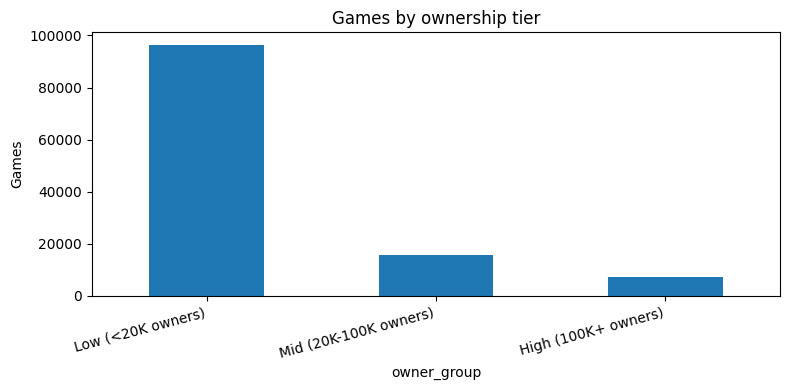

owner_group,Low (<20K owners),Mid (20K-100K owners),High (100K+ owners)
release_year,,,
2015,38.2,34.9,27.0
2016,49.5,30.1,20.5
2017,64.3,23.6,12.2
2018,71.6,20.0,8.4
2019,75.0,16.9,8.1
2020,72.1,19.3,8.6
2021,76.1,17.2,6.7
2022,80.4,14.8,4.8
2023,84.4,11.3,4.3


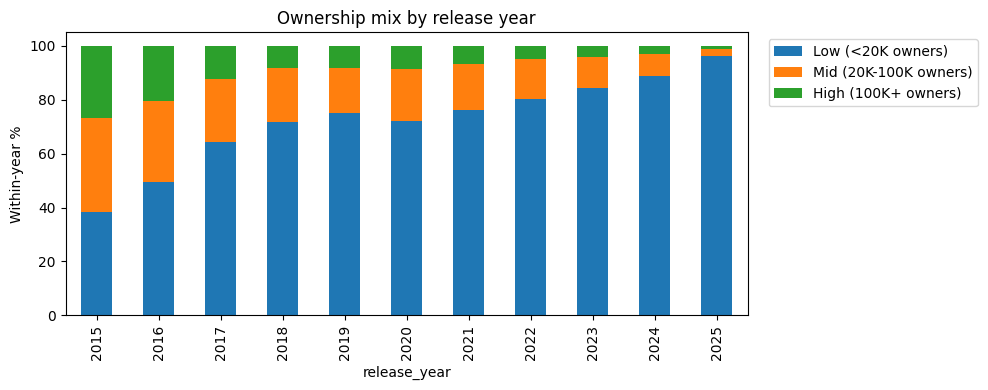

In [3]:
order = ['Low (<20K owners)', 'Mid (20K-100K owners)', 'High (100K+ owners)']
counts = df.owner_group.value_counts().reindex(order, fill_value=0)
display(pd.DataFrame({'n': counts, 'pct': (100*counts/len(df)).round(2)}))
ax=counts.plot.bar(figsize=(8,4), title='Games by ownership tier')
ax.set_ylabel('Games'); plt.xticks(rotation=15,ha='right');plt.tight_layout();plt.show()
cohort=pd.crosstab(df.release_year, df.owner_group).reindex(columns=order,fill_value=0)
display((100*cohort.div(cohort.sum(axis=1),axis=0)).round(1))
(cohort.div(cohort.sum(axis=1),axis=0)*100).plot.bar(stacked=True,figsize=(10,4))
plt.ylabel('Within-year %');plt.title('Ownership mix by release year');plt.legend(bbox_to_anchor=(1.02,1));plt.tight_layout();plt.show()

## 3. Genre and Gameplay features (supervised and clustering)

Binary genre/category indicators represent product design and are interpretable predictors. Their prevalence and conditional ownership composition can reveal useful signals, but very rare features may be unstable and highly overlapping indicators can distort clustering.

,percent_of_games
lang_english,88.7
cat_single_player,87.9
genre_indie,66.3
cat_achievements,45.4
genre_casual,41.5
genre_action,37.5
genre_adventure,37.0
cat_controller_support,31.8
lang_chinese,29.2
lang_japanese,24.1


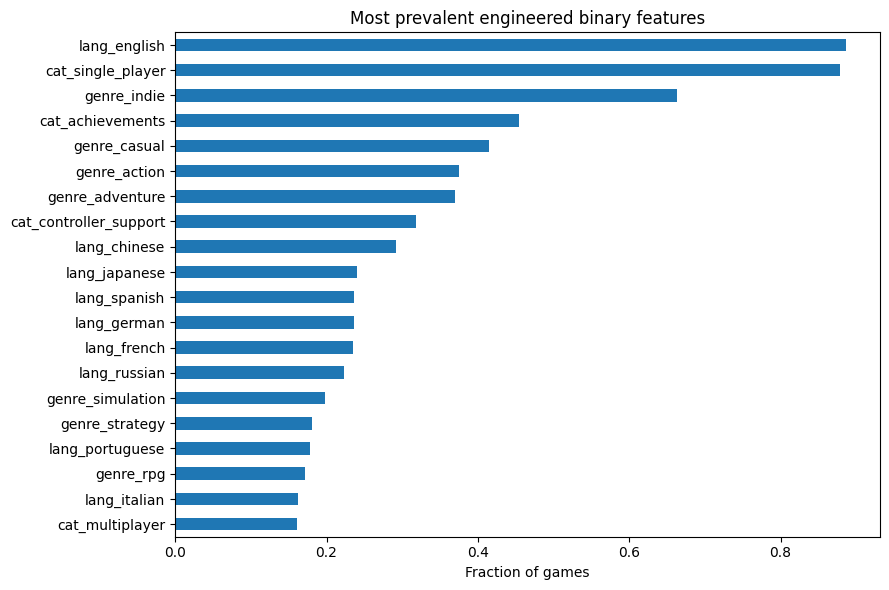

,feature,n_present,high_rate_present,high_rate_absent,difference_pp
33,cat_trading_cards,10061,0.309,0.036,27.228
35,cat_workshop,2447,0.269,0.055,21.436
36,cat_in_app_purchases,2953,0.218,0.055,16.277
29,cat_mmo,1274,0.208,0.058,15.026
27,cat_online,12143,0.159,0.048,11.044
16,genre_massively_multiplayer,2456,0.164,0.057,10.694
8,lang_italian,19251,0.149,0.042,10.649
4,lang_german,28059,0.140,0.035,10.509
5,lang_french,27960,0.139,0.035,10.366
3,lang_spanish,28150,0.136,0.036,10.084


In [4]:
binary_cols=[c for c in df if c.startswith(('genre_','cat_','lang_'))]
prevalence=df[binary_cols].apply(pd.to_numeric,errors='coerce').mean().sort_values(ascending=False)
display((100*prevalence).round(1).rename('percent_of_games').head(25).to_frame())
prevalence.head(20).sort_values().plot.barh(figsize=(9,6),title='Most prevalent engineered binary features')
plt.xlabel('Fraction of games');plt.tight_layout();plt.show()
rows=[]
for c in binary_cols:
    flag=pd.to_numeric(df[c],errors='coerce').fillna(0).eq(1)
    if flag.sum()>=100:
        rows.append((c,int(flag.sum()),float(df.loc[flag,'owner_group'].eq(order[2]).mean()),float(df.loc[~flag,'owner_group'].eq(order[2]).mean())))
assoc=pd.DataFrame(rows,columns=['feature','n_present','high_rate_present','high_rate_absent'])
assoc['difference_pp']=100*(assoc.high_rate_present-assoc.high_rate_absent)
display(assoc.reindex(assoc.difference_pp.abs().sort_values(ascending=False).index).head(20).round(3))

## 4. Publisher, Developer & Language

Prior release history is available conceptually before launch, while language/platform breadth may reflect distribution strategy. Current price is a snapshot measurement, not necessarily the launch price; evaluate it descriptively and exclude it from a strict prelaunch model.

owner_group,Low (<20K owners),Mid (20K-100K owners),High (100K+ owners)
pub_prior_games_max,0.00,1.00,2.00
pub_prior_games_mean,0.00,1.00,2.00
dev_prior_games_max,0.00,0.00,0.00
dev_prior_games_mean,0.00,0.00,0.00
total_langs,1.00,2.00,6.00
other_langs,0.00,0.00,0.00
num_platforms,1.00,1.00,1.00
num_game_genres,3.00,3.00,3.00
price,1.99,2.49,3.74
age,3.22,5.81,6.58


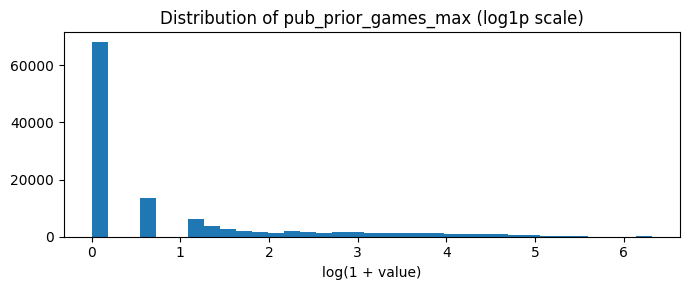

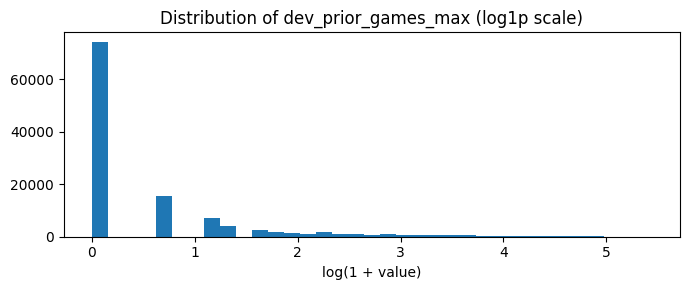

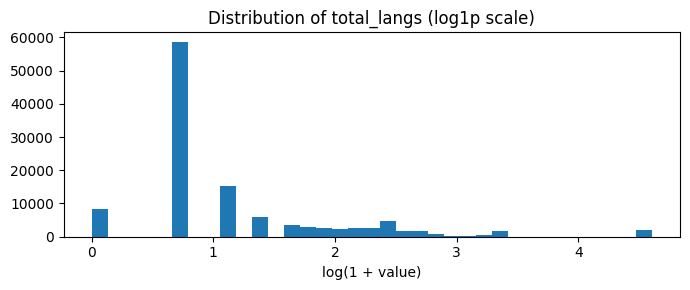

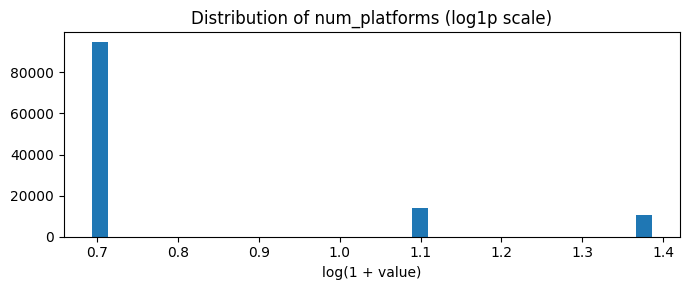

In [5]:
candidates=['pub_prior_games_max','pub_prior_games_mean','dev_prior_games_max','dev_prior_games_mean','total_langs','other_langs','num_platforms','num_game_genres','price','age']
num=[c for c in candidates if c in df]
display(df.groupby('owner_group')[num].median().reindex(order).T.round(2))
for c in [x for x in ['pub_prior_games_max','dev_prior_games_max','total_langs','num_platforms'] if x in df]:
    v=pd.to_numeric(df[c],errors='coerce').clip(lower=0)
    fig,ax=plt.subplots(figsize=(7,3));ax.hist(np.log1p(v.dropna()),bins=35)
    ax.set_title(f'Distribution of {c} (log1p scale)');ax.set_xlabel('log(1 + value)');plt.tight_layout();plt.show()

## 5. Metacritic selection and possible leakage

Scores may be available for only a small and nonrandom subset. Scores, user reviews, recommendations, peak CCU, and current ownership are potentially post-release outcomes, so do not use them as predictors for a prelaunch success forecast.

In [6]:
if 'has_metacritic_score' in df:
    tab=pd.crosstab(df.has_metacritic_score,df.owner_group).reindex(columns=order,fill_value=0)
    display(tab)
    display((100*tab.div(tab.sum(axis=1),axis=0)).round(1))
    print('Metacritic availability:',round(100*df.has_metacritic_score.mean(),2),'%')
if 'metacritic_score' in df and 'has_metacritic_score' in df:
    display(df.loc[df.has_metacritic_score.eq(1)].groupby('owner_group').metacritic_score.agg(['count','median','mean']).reindex(order).round(2))

owner_group,Low (<20K owners),Mid (20K-100K owners),High (100K+ owners)
has_metacritic_score,,,
0,95834,14857,5534
1,535,745,1531


owner_group,Low (<20K owners),Mid (20K-100K owners),High (100K+ owners)
has_metacritic_score,,,
0,82.5,12.8,4.8
1,19.0,26.5,54.5


Metacritic availability: 2.36 %


,count,median,mean
owner_group,,,
Low (<20K owners),535,75.0,72.28
Mid (20K-100K owners),745,73.0,71.41
High (100K+ owners),1531,78.0,76.75


## 6. Feature Scaling and Redundancy Checks

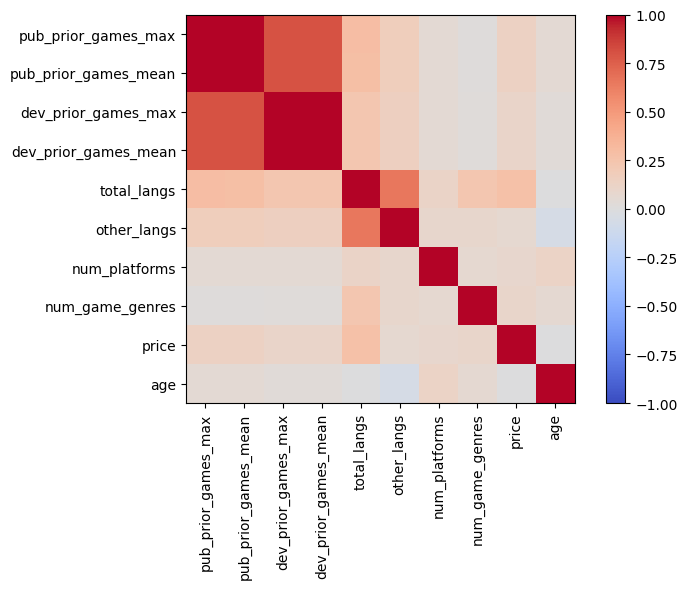

Binary features with <1% prevalence: 2 of 37


In [8]:
numeric=[c for c in ['pub_prior_games_max','pub_prior_games_mean','dev_prior_games_max','dev_prior_games_mean','total_langs','other_langs','num_platforms','num_game_genres','price','age'] if c in df]
if len(numeric)>1:
    corr=df[numeric].apply(pd.to_numeric,errors='coerce').corr(method='spearman')
    fig,ax=plt.subplots(figsize=(8,6));im=ax.imshow(corr,vmin=-1,vmax=1,cmap='coolwarm');ax.set_xticks(range(len(numeric)),numeric,rotation=90);ax.set_yticks(range(len(numeric)),numeric);fig.colorbar(im,ax=ax);plt.tight_layout();plt.show()
print('Binary features with <1% prevalence:',int((prevalence<.01).sum()),'of',len(prevalence))

The primary concern is redundancy among publisher and developer experience features. However, strong correlation does not automatically mean a feature should be removed. Feature selection should also consider whether each variable captures a meaningful distinction.

The heatmap does not assess differences in feature scales, so scaling and weighting should still be considered separately.